**DESCRIPCIÓN DEL DATASET**

Descripción. Datos de las campañas de telemarketing de un banco portugués, de mayo de 2008 a noviembre de 2010, con las que se ofrecía un depósito a plazo.

Fuente. UCI Machine Learning Repository, Bank Marketing, archivo bank-additional-full.csv dentro de bank-additional.zip.

Cita. Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22-31.

Licencia. CC BY 4.0.

In [3]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", __import__("matplotlib").__version__)
print("seaborn     ", sns.__version__)
print("scikit-learn", sklearn.__version__)

SEMILLA = 42  # fija la partición para que los resultados se repitan

numpy        2.1.3
pandas       2.2.3
matplotlib   3.10.0
seaborn      0.13.2
scikit-learn 1.6.1


**1. Antes de modelar, revisa bank-additional-names.txt. ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar? Quítala y explica por qué.**

El mismo documento bank-additional-names.txt advierte que la variable duration, la duración de la última llamada en segundos, no se conoce antes de llamar. Solo existe cuando la llamada ya terminó, y en ese momento también se sabe si el cliente aceptó, por lo que el modelo estaría usando información del resultado para predecirlo. Por eso se quita antes de modelar.

In [4]:
# Cargar datos
df = pd.read_csv("/content/drive/MyDrive/INTRODUCCIÓN A LA CIENCIA DE DATOS/practicas/Notebook de metricas/bank-additional-full.csv", sep=";")
# Quitar la variable que el banco no conoce antes de llamar
df_modelo = df.drop(columns="duration")

print("Original:", df.shape)
print("Sin duration:", df_modelo.shape)

Original: (41188, 21)
Sin duration: (41188, 20)


**2. Aparta 20 % de los datos para prueba, con una partición estratificada. ¿Qué exactitud obtiene un clasificador que siempre responde no? ¿Qué dice eso de la exactitud como métrica en este problema?**


In [5]:
from sklearn.model_selection import train_test_split

variable_objetivo = "y"
X = df_modelo.drop(columns=variable_objetivo)
y = df_modelo[variable_objetivo]

X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.DataFrame({
    "distribución previo a la separación": y.value_counts(normalize=True),
    "entrenamiento": y_entrena.value_counts(normalize=True),
    "prueba": y_prueba.value_counts(normalize=True),
}).round(3)

,distribución previo a la separación,entrenamiento,prueba
y,,,
no,0.887,0.887,0.887
yes,0.113,0.113,0.113


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

base = DummyClassifier(strategy="most_frequent").fit(X_entrena, y_entrena)
pred_base = base.predict(X_prueba)

print(f"Siempre predice: {pred_base[0]}")
print(f"Exactitud:       {accuracy_score(y_prueba, pred_base):.3f}")

Siempre predice: no
Exactitud:       0.887


El clasificador que siempre responde “no” obtiene una exactitud de 0.887 sin mirar a un cliente, y nunca identifica a nadie que vaya a aceptar. Con clases desbalanceadas, la exactitud sale alta aunque el modelo no sirva para lo que el banco necesita, que es encontrar a los clientes que sí aceptarían. Por eso la exactitud sola no basta en este problema.

**3. Ajusta una regresión logística, con las variables categóricas en one-hot y el escalado dentro de un Pipeline. Con el umbral de 0.5, reporta en prueba la matriz de confusión y, a partir de ella, exactitud, precisión, sensibilidad, especificidad y F1. ¿Cuál de esas métricas le importa más al banco, y por qué?**

Según la documentación, en pdays el valor 999 indica que el cliente no había sido contactado en una campaña anterior, por lo que no corresponde a una cantidad real de días. En este análisis no se le aplica ningún tratamiento porque la tarea no lo solicita, y la variable entra al modelo tal como viene. El escalado lo trata como si fueran 999 días, un valor muy alejado del resto. En análisis futuros convendría manejarlo como un caso aparte, por ejemplo con una columna indicadora y un valor de reemplazo.

In [9]:
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

variables_categoricas = X_entrena.select_dtypes(exclude="number").columns.tolist()
variables_numericas = X_entrena.select_dtypes(include="number").columns.tolist()

print("Categóricas:", variables_categoricas)
print("Numéricas:  ", variables_numericas)

preprocesamiento = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), variables_categoricas),
    (StandardScaler(), variables_numericas),
)

logistica = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(C=np.inf, max_iter=5000)),
])
logistica.fit(X_entrena, y_entrena)

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numéricas:   ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed'])])),
                ('modelo', LogisticRegression(C=inf, max_iter=5000))])

Quedan 10 variables categóricas, que pasan a one-hot, y 9 numéricas, que se estandarizan. Las dos transformaciones y la regresión logística quedan dentro del mismo Pipeline.

[[7218   92]
 [ 725  203]]


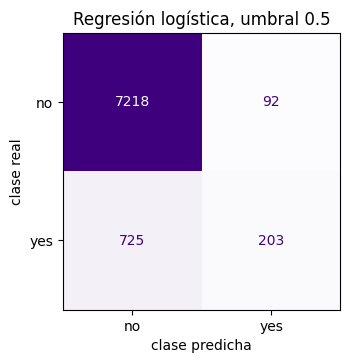

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

clases = ["no", "yes"]
pred = logistica.predict(X_prueba)  # predict usa el umbral de 0.5
matriz = confusion_matrix(y_prueba, pred, labels=clases)
print(matriz)

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
ax.set_title("Regresión logística, umbral 0.5")
plt.show()

De los 928 clientes de prueba que aceptaron, el modelo detecta 203 y deja pasar 725. De los 7310 que no aceptaron, marca solo a 92 como posibles clientes. Con el umbral de 0.5 el modelo casi nunca dice “sí”, predice positivos 295 de 8238 clientes.

Las métricas se calculan a partir de las cuatro celdas de la matriz.

In [17]:
vn, fp, fn, vp = matriz.ravel()

exactitud = (vp + vn) / (vp + vn + fp + fn)
precision = vp / (vp + fp)
sensibilidad = vp / (vp + fn)
especificidad = vn / (vn + fp)
f1 = 2 * precision * sensibilidad / (precision + sensibilidad)

print(f"Exactitud:       {exactitud:.3f}")
print(f"Precisión:       {precision:.3f}")
print(f"Sensibilidad:    {sensibilidad:.3f}")
print(f"Especificidad:   {especificidad:.3f}")
print(f"F1:              {f1:.3f}")

Exactitud:       0.901
Precisión:       0.688
Sensibilidad:    0.219
Especificidad:   0.987
F1:              0.332


La exactitud es 0.901, apenas por encima del 0.887 del clasificador que siempre dice “no”. El modelo casi no se equivoca con los clientes que no aceptan (especificidad de 0.987), y cuando marca a alguien como positivo acierta en 69 % de los casos (precisión de 0.688). Su punto débil es la sensibilidad, de 0.219, porque solo encuentra a uno de cada cinco clientes que sí aceptarían, y eso deja el F1 en 0.332.

**¿Cuál de esas métricas le importa más al banco, y por qué?**

Al banco le importa más la sensibilidad, porque su objetivo es encontrar a los clientes que aceptarían el depósito. Dejar pasar a uno de ellos le cuesta un ingreso de 50, mientras que llamar a alguien que no acepta solo le cuesta los 5 de la llamada. Con una sensibilidad de 0.219, este modelo deja sin llamar a casi cuatro de cada cinco clientes que sí habrían aceptado.

**4. Grafica la curva ROC y la curva de precisión contra sensibilidad, con su AUC y su precisión promedio. En scikit-learn, RocCurveDisplay y PrecisionRecallDisplay. ¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?**

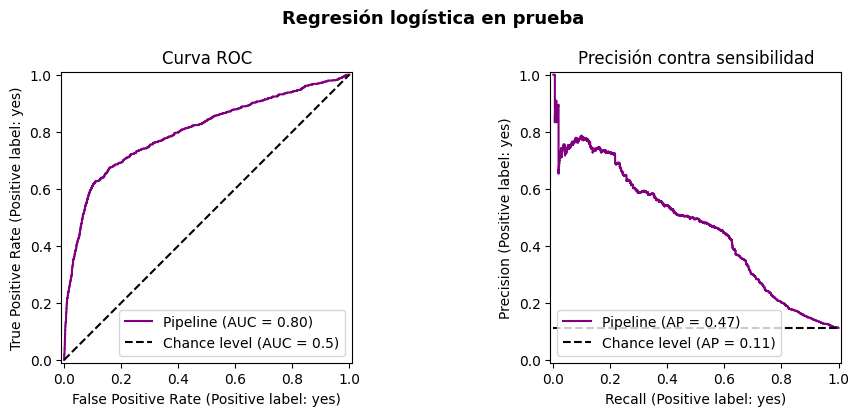

AUC:                  0.801
Precisión promedio:   0.465
Proporción de 'yes':  0.113


In [12]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score, average_precision_score

p_prueba = logistica.predict_proba(X_prueba)[:, 1]  # probabilidad de "yes"

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
RocCurveDisplay.from_estimator(logistica, X_prueba, y_prueba, pos_label="yes",
                               ax=axes[0], color="purple", plot_chance_level=True)
PrecisionRecallDisplay.from_estimator(logistica, X_prueba, y_prueba, pos_label="yes",
                                      ax=axes[1], color="purple", plot_chance_level=True)
axes[0].set_title("Curva ROC")
axes[1].set_title("Precisión contra sensibilidad")
fig.suptitle("Regresión logística en prueba", fontsize=13, color="black", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"AUC:                  {roc_auc_score(y_prueba, p_prueba):.3f}")
print(f"Precisión promedio:   {average_precision_score(y_prueba, p_prueba, pos_label='yes'):.3f}")
print(f"Proporción de 'yes':  {(y_prueba == 'yes').mean():.3f}")

El AUC es 0.801, así que la curva ROC queda bien por encima de la diagonal. En la curva de precisión contra sensibilidad, la precisión promedio es 0.465, unas cuatro veces la línea de azar de 0.113. Aun así, la precisión cae rápido conforme sube la sensibilidad.

**¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?**

La curva de precisión contra sensibilidad muestra cuántas falsas alarmas hay por cada cliente que sí acepta, algo que la ROC no. La ROC mide los falsos positivos como proporción de los 7310 clientes que no aceptan, así que muchas llamadas inútiles se ven como una tasa pequeña.

**5. Cada llamada cuesta 5, acepte o no el cliente, y cada cliente que acepta deja un ingreso de 50. ¿A partir de qué probabilidad conviene llamar? Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.**

In [13]:
acepta = (y_prueba == "yes").to_numpy()

filas = []
for umbral in [0.5, 0.1]:
    llamar = p_prueba >= umbral
    vp = (llamar & acepta).sum()
    fp = (llamar & ~acepta).sum()
    filas.append({"umbral": umbral,
                  "llamadas": vp + fp,
                  "aceptan": vp,
                  "no aceptan": fp,
                  "aceptarían sin llamada": (~llamar & acepta).sum(),
                  "ganancia": 50 * vp - 5 * (vp + fp)})

pd.DataFrame(filas)

,umbral,llamadas,aceptan,no aceptan,aceptarían sin llamada,ganancia
0,0.5,295,203,92,725,8675
1,0.1,1900,632,1268,296,22100


Con el umbral de 0.5 el banco llama a 295 clientes, de los que aceptan 203, y gana 8675. Con el umbral de 0.1 llama a 1900, aceptan 632 y la ganancia sube a 22 100, más del doble. Las llamadas inútiles pasan de 92 a 1268, pero cada una cuesta solo 5, mientras que los 429 clientes adicionales que aceptan dejan 45 cada uno. Los clientes que habrían aceptado y no se llaman bajan de 725 a 296.


**6. La variable que quitaste. Repite el punto 3 incluyéndola. ¿Qué les pasa a las métricas? ¿Le servirían al banco?**

Mismos clientes en prueba: True
[[7143  167]
 [ 523  405]]


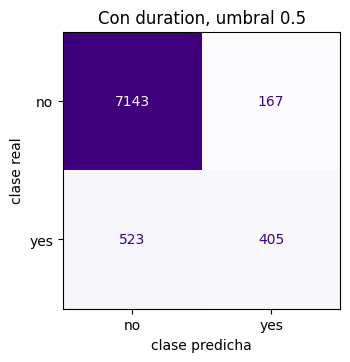

In [14]:
X_con = df.drop(columns=variable_objetivo)
y_con = df[variable_objetivo]

X_entrena_con, X_prueba_con, y_entrena_con, y_prueba_con = train_test_split(
    X_con, y_con, test_size=0.2, stratify=y_con, random_state=SEMILLA)

print("Mismos clientes en prueba:", (X_prueba_con.index == X_prueba.index).all())

preprocesamiento_con = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), variables_categoricas),
    (StandardScaler(), variables_numericas + ["duration"]),
)

logistica_con = Pipeline([
    ("preprocesamiento", preprocesamiento_con),
    ("modelo", LogisticRegression(C=np.inf, max_iter=5000)),
])
logistica_con.fit(X_entrena_con, y_entrena_con);

pred_con = logistica_con.predict(X_prueba_con)
matriz_con = confusion_matrix(y_prueba_con, pred_con, labels=clases)
print(matriz_con)

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(matriz_con, display_labels=clases).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
ax.set_title("Con duration, umbral 0.5")
plt.show()

Con duration, el modelo detecta 405 de los 928 clientes que aceptaron, el doble que sin ella (203). A cambio marca a 167 clientes que no aceptaron, contra 92 antes.

In [15]:
def metricas(matriz):
    vn, fp, fn, vp = matriz.ravel()
    precision = vp / (vp + fp)
    sensibilidad = vp / (vp + fn)
    return {"exactitud": (vp + vn) / matriz.sum(),
            "precisión": precision,
            "sensibilidad": sensibilidad,
            "especificidad": vn / (vn + fp),
            "F1": 2 * precision * sensibilidad / (precision + sensibilidad)}

pd.DataFrame({
    "sin duration": metricas(matriz),
    "con duration": metricas(matriz_con),
}).round(3)

,sin duration,con duration
exactitud,0.901,0.916
precisión,0.688,0.708
sensibilidad,0.219,0.436
especificidad,0.987,0.977
F1,0.332,0.540


Con duration mejoran casi todas las métricas. La sensibilidad se duplica, de 0.219 a 0.436, y el F1 sube de 0.332 a 0.540. La exactitud pasa de 0.901 a 0.916 y la precisión de 0.688 a 0.708. Solo la especificidad baja un poco, de 0.987 a 0.977, por las falsas alarmas adicionales.

Al incluir duration las métricas mejoran, sobre todo la sensibilidad y el F1, porque la duración de la llamada está muy ligada a su resultado. Pero ese modelo no le serviría al banco. Para conocer la duración primero hay que llamar, y al terminar la llamada el banco ya sabe si el cliente aceptó, así que el modelo no ayuda a decidir a quién llamar. Su desempeño solo sirve como referencia de lo que se lograría con información que no está disponible al momento de decidir.

**Declaración de uso de IA**

Este notebook fue elaborado con apoyo de Claude (Anthropic) para resolver dudas sobre código y redacción. La interpretación de los resultados y la revisión final son responsabilidad del autor.